# 01 — From main sequence to white dwarf

The goal is to evolve a single ZAMS (Zero-Age Main Sequence) star with  SeBa in AMUSE.

Chapter 5 of the AMUSE book is good to read for this


In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from amuse.community.seba import Seba
from amuse.datamodel import Particle
from amuse.units import units


def locate_project_root():
    """Locate the project root independently of the notebook working directory. This is useful for running notebooks from whatever directory you want to work from."""
    cwd = Path.cwd().resolve()

    for parent in (cwd, *cwd.parents):
        for candidate in (parent, parent / "white_dwarf_project"):
            if (candidate / "notebooks" / "01_stellar_evolution.ipynb").is_file():
                return candidate

    raise FileNotFoundError(
        f"Cannot locate white_dwarf_project from {cwd}"
    )


ROOT = locate_project_root()
DATA_DIR = ROOT / "data"
FIGURE_DIR = ROOT / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)


Project root: /home/armand/Sync/Master-Leiden/Y1/Simulation&Modelingin Astropthisics/Assignements/white_dwarf_project


## 1. Choose a progenitor star

A 1.2 solar-mass progenitor as an initial demonstration. We should eventually compare progenitor tracks and select those compatible with the star the micro-lensing event observed (I think 0.49 solar masses?).

In [2]:
M_INITIAL = 1.2 | units.MSun
METALLICITY = 0.02
MAX_AGE = 14000 | units.Myr
MAX_STEPS = 60000

#Noting down here the AMUSE stellar_type IDs: 3 first giant branch, 5/6 AGB, 10/11/12 white dwarfs.
#You can check in the block below which stellar type the remnant is at the end of the evolution (Spoiler alert: It's 11, a CO white dwarf, as expected))
WHITE_DWARF_TYPES = {10, 11, 12}

#The numbers below will need to be adjusted if we change the stellar evolution code.
def next_output_step(stellar_type):
    """Pilot time sampling: finer output near giant and AGB phases since they evolve faster"""
    if stellar_type in (5, 6):
        return 0.01 | units.Myr  # AGB: 10 kyr
    if stellar_type in (2, 3):
        return 0.2 | units.Myr   # HG / RGB: 200 kyr
    if stellar_type == 4:
        return 0.5 | units.Myr   # Core He burning
    return 5 | units.Myr          # Main sequence


## 2. Run SeBa

We use `stellar.evolve_model(target_time)` and inspect the particle inside the SeBa worker. We stop the worker in a `finally` block so an interrupted calculation does not leave a process behind. The timestep used below determines when we save outputs that SeBa produces anyways, it handles its own timesteps internally.

In [3]:
stellar = Seba()
records = []
start = perf_counter()

try:
    stellar.parameters.metallicity = METALLICITY
    star = stellar.particles.add_particle(Particle(mass=M_INITIAL))

    def save_current_state():
        records.append({
            "time_Myr": float(stellar.model_time.value_in(units.Myr)),
            "mass_MSun": float(star.mass.value_in(units.MSun)),
            "radius_RSun": float(star.radius.value_in(units.RSun)),
            "luminosity_LSun": float(star.luminosity.value_in(units.LSun)),
            "stellar_type": int(star.stellar_type.value_in(units.stellar_type)),
        })

    save_current_state()
    for _ in range(MAX_STEPS):
        kind = records[-1]["stellar_type"]
        if kind in WHITE_DWARF_TYPES or stellar.model_time >= MAX_AGE:
            break

        target = stellar.model_time + next_output_step(kind)
        if target > MAX_AGE:
            target = MAX_AGE

        stellar.evolve_model(target)
        save_current_state()
    else:
        raise RuntimeError("MAX_STEPS reached before WD formation or MAX_AGE.")
finally:
    stellar.stop()

track = {key: np.array([row[key] for row in records]) for key in records[0]}
print(f"Saved {len(records):,} stellar states.")
print(f"Elapsed wall time: {perf_counter()-start:.2f} s")
print(f"Final time: {track['time_Myr'][-1]/1000:.3f} Gyr")
print(f"Final mass: {track['mass_MSun'][-1]:.3f} Msun")
print(f"Final stellar type: {track['stellar_type'][-1]}")
print("White dwarf reached:", track["stellar_type"][-1] in WHITE_DWARF_TYPES)


Saved 5,640 stellar states.
Elapsed wall time: 11.60 s
Final time: 6.514 Gyr
Final mass: 0.532 Msun
Final stellar type: 11
White dwarf reached: True


## 3. Plot the evolution

One plot to show when the star increases its radius, when mass is lost, and when it becomes a compact remnant. The horizontal dashed line marks a 1-au radius around which we will probably place our planet.

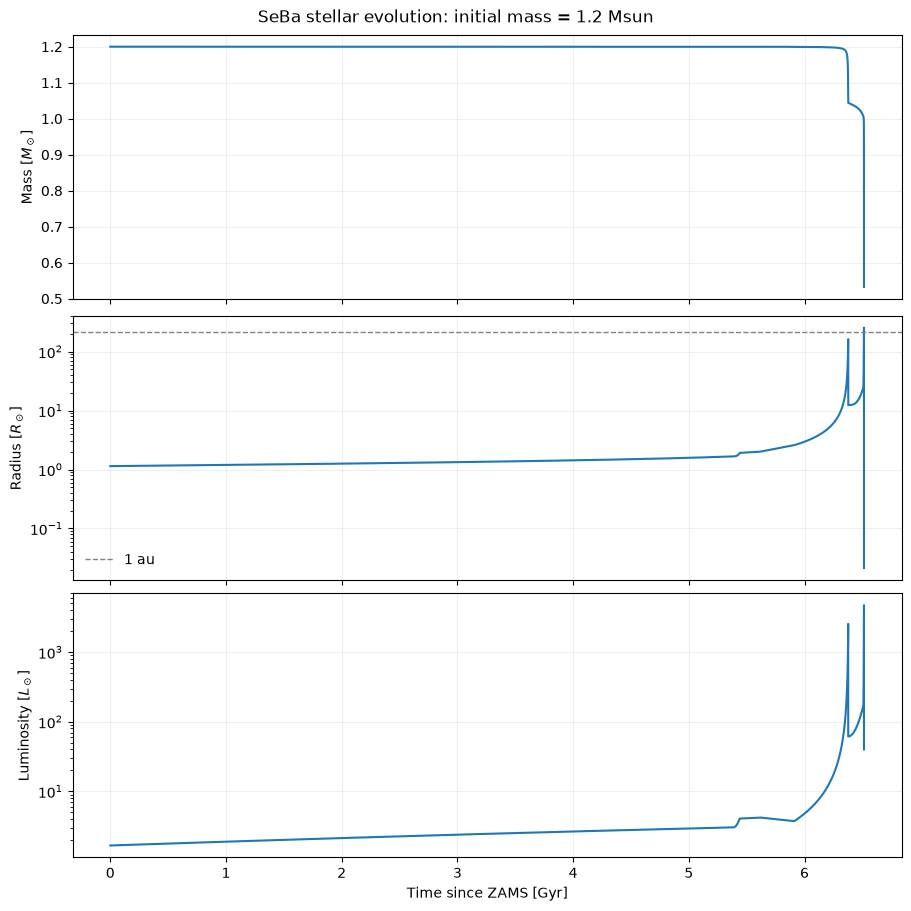

Figure saved: /home/armand/Sync/Master-Leiden/Y1/Simulation&Modelingin Astropthisics/Assignements/white_dwarf_project/figures/stellar_evolution_pilot.pdf


In [4]:
# I will note down here that the radius crossing 1 AU does not mean the planet is engulfed, since the star will have lost a lot of mass by then
#  and the planet will have moved outwards. But it is a good indicator of when the star is in its giant phases and when the planet is at risk of being engulfed.

time_Gyr = track["time_Myr"] / 1000
mass = track["mass_MSun"]
radius = track["radius_RSun"]
luminosity = track["luminosity_LSun"]

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True, constrained_layout=True)

axes[0].plot(time_Gyr, mass)
axes[0].set_ylabel(r"Mass [$M_\odot$]")

axes[1].plot(time_Gyr, radius)
axes[1].axhline(
    (1 | units.au).value_in(units.RSun),
    linestyle="--", linewidth=1, color="gray", label="1 au",
)
axes[1].set_yscale("log")
axes[1].set_ylabel(r"Radius [$R_\odot$]")
axes[1].legend(frameon=False)

axes[2].plot(time_Gyr, luminosity)
axes[2].set_yscale("log")
axes[2].set_ylabel(r"Luminosity [$L_\odot$]")
axes[2].set_xlabel("Time since ZAMS [Gyr]")

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle(f"SeBa stellar evolution: initial mass = {M_INITIAL.value_in(units.MSun):g} Msun")
output_figure = FIGURE_DIR / "stellar_evolution_pilot.pdf"
fig.savefig(output_figure, bbox_inches="tight")
plt.show()
print("Figure saved:", output_figure)


## 4. Diagnostics report

The maximal stellar radius is a useful diagnostic for engulfment. It is not validated until we refine the output cadence, especially near the AGB radius maximum.

In [5]:
imax = int(np.argmax(radius))
print(f"Maximum sampled radius: {radius[imax]:.2f} Rsun")
print(f"                         {radius[imax] * (1 | units.RSun).value_in(units.au):.3f} au")
print(f"At time: {time_Gyr[imax]:.4f} Gyr")
print(f"Stellar type at max radius: {track['stellar_type'][imax]}")

wd_indices = np.flatnonzero(np.isin(track['stellar_type'], list(WHITE_DWARF_TYPES)))
if len(wd_indices):
    iwd = int(wd_indices[0])
    print(f"First sampled WD stage: {time_Gyr[iwd]:.4f} Gyr")
    print(f"White dwarf mass: {mass[iwd]:.4f} Msun")
else:
    print("No WD phase reached; try adjusting initial mass or MAX_AGE.")


Maximum sampled radius: 254.83 Rsun
                         1.185 au
At time: 6.5139 Gyr
Stellar type at max radius: 5
First sampled WD stage: 6.5139 Gyr
White dwarf mass: 0.5324 Msun


## 5. Save data for followup

We store NumPy arrays for plots and analytical tests. Later, particle-based runs can use AMUSE's native HDF5 output.

In [6]:
output_data = DATA_DIR / "stellar_track_pilot.npz"
np.savez_compressed(
    output_data,
    **track,
    initial_mass_MSun=M_INITIAL.value_in(units.MSun),
    metallicity=METALLICITY,
)
print("Saved stellar track:", output_data)


Saved stellar track: /home/armand/Sync/Master-Leiden/Y1/Simulation&Modelingin Astropthisics/Assignements/white_dwarf_project/data/stellar_track_pilot.npz


### Stuff we still need to do here

1. Refine the giant-phase sampling and verify the maximum radius converges.
2. Check other initial masses and identify tracks reaching a WD mass near (probably) 0.49 Msun.
3. Consider SeBa versus SSE differences. Is MESA an option?